# Analys av hälsodata

## Introduktion

Syftet med denna analys är att undersöka ett hälsorelaterat dataset med hjälp av Python.

Analysen omfattar beskrivande statistik, visualiseringar, simuleringar, konfidensintervall och hypotesprövning.

Datasetet innehåller information om bland annat ålder, kön, vikt, blodtryck, kolesterol, rökning och sjukdom.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
from scipy import stats

# Slump-seed för reproducerbara resultat
np.random.seed(42)

# Separat slumpgenerator för simuleringar
rng = np.random.default_rng(seed=42)

## 1. Läs in och undersök data

Vi läser in datasetet och undersöker dess struktur, kolumner och innehåll.

In [2]:
df = pd.read_csv("health_study_dataset.csv")

df.columns = df.columns.str.strip()

print(df.head())
df.info()

   id  age   sex  height  weight  systolic_bp  cholesterol   smoker  disease
0   1   57   F     168.9    65.8        141.8         4.58   No            0
1   2   47   M     180.4    95.9        144.8         5.18   Yes           0
2   3   59   F     169.9    82.2        151.7         6.16   No            0
3   4   72   M     157.7    93.1        151.0         6.63   No            0
4   5   46   M     192.6   104.1        144.1         5.21   No            0
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non

## 2. Beskrivande analys

Vi undersöker datasetets numeriska variabler och använder statistik och grafer för att beskriva datan.

Först kontrollerar vi kategorierna för kön och rökning.

In [3]:
df["sex"] = df["sex"].str.strip()
df["smoker"] = df["smoker"].str.strip()

print("Kön:", df["sex"].unique())
print("Rökning:", df["smoker"].unique())

Kön: <StringArray>
['F', 'M']
Length: 2, dtype: str
Rökning: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


### 2.1 Beskrivande statistik

Vi beräknar medelvärde, median, min och max för ålder, vikt, längd, systoliskt blodtryck och kolesterol.

In [4]:
columns_to_analyze = [
    "age",
    "weight",
    "height",
    "systolic_bp",
    "cholesterol"
]

descriptive_stats = df[columns_to_analyze].agg(
    ["mean", "median", "min", "max"]
)

descriptive_stats

,age,weight,height,systolic_bp,cholesterol
mean,49.42625,73.413,171.84925,149.178625,4.92915
median,50.00000,73.200,171.35000,149.400000,4.97000
min,18.00000,33.700,144.40000,106.800000,2.50000
max,90.00000,114.400,200.40000,185.900000,7.88000


### 2.2 Visualiseringar

Vi använder tre olika diagram för att undersöka fördelningen av blodtryck, skillnader i vikt mellan könen och sambandet mellan ålder och blodtryck.

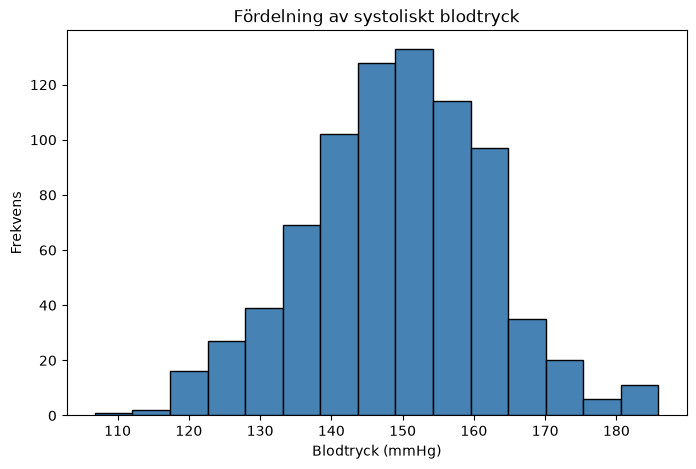

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["systolic_bp"].dropna(),
    bins=15,
    color="steelblue",
    edgecolor="black"
)

plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Blodtryck (mmHg)")
plt.ylabel("Frekvens")

plt.show()

Histogrammet visar hur blodtrycksvärdena fördelar sig. Varje stapel representerar ett intervall av blodtrycksvärden.

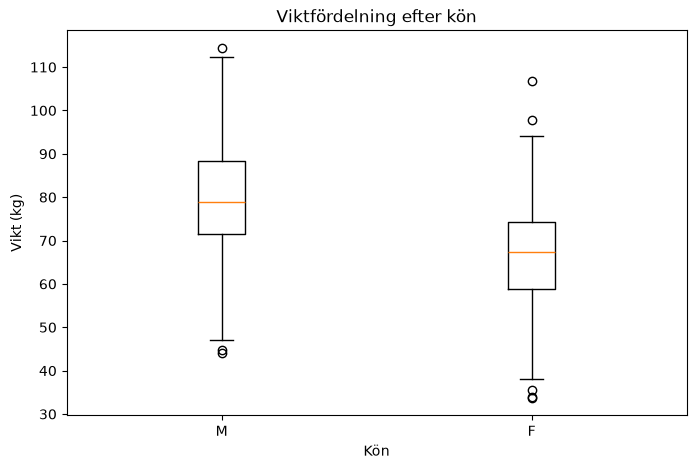

In [6]:
weight_m = df[df["sex"] == "M"]["weight"].dropna()
weight_f = df[df["sex"] == "F"]["weight"].dropna()

plt.figure(figsize=(8, 5))

plt.boxplot(
    [weight_m, weight_f],
    tick_labels=["M", "F"]
)

plt.title("Viktfördelning efter kön")
plt.xlabel("Kön")
plt.ylabel("Vikt (kg)")

plt.show()

Boxploten gör det möjligt att jämföra median, spridning och eventuella extremvärden mellan grupperna.

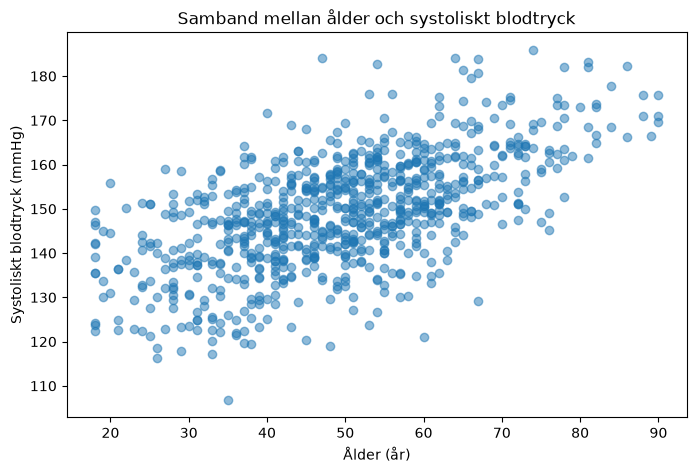

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["age"],
    df["systolic_bp"],
    alpha=0.5
)

plt.title("Samband mellan ålder och systoliskt blodtryck")
plt.xlabel("Ålder (år)")
plt.ylabel("Systoliskt blodtryck (mmHg)")

plt.show()

Varje punkt representerar en person. Grafen hjälper oss att undersöka om det finns ett samband mellan ålder och systoliskt blodtryck.

### 2.3 Korrelation mellan ålder och blodtryck

Vi beräknar Pearsons korrelationskoefficient för att undersöka styrkan och riktningen på det linjära sambandet mellan ålder och systoliskt blodtryck.

In [8]:
correlation = df["age"].corr(df["systolic_bp"])

print("Korrelation:", correlation)

Korrelation: 0.60757847098565


### Tolkning av korrelationen

Korrelationskoefficienten är cirka 0,608, vilket visar ett positivt linjärt samband mellan ålder och systoliskt blodtryck.

Det innebär att personer med högre ålder tenderar att ha högre systoliskt blodtryck i datasetet. Korrelationen visar däremot inte att åldern orsakar ett högre blodtryck.

## 3. Simulering kopplad till hälsodata

Vi beräknar först andelen personer i datasetet som har sjukdomen. Därefter använder vi denna andel som sannolikhet i en simulering av 1 000 slumpade personer.

In [9]:
disease_proportion = df["disease"].mean()

print("Andel med sjukdom:", disease_proportion)
print("Andel i procent:", disease_proportion * 100)

Andel med sjukdom: 0.05875
Andel i procent: 5.875


### 3.1 Simulering av 1 000 personer

Vi använder sannolikheten från datasetet för att simulera 1 000 slumpade personer.

Varje person får värdet 1 (sjukdom) eller 0 (ingen sjukdom).

In [10]:
simulated_disease = rng.binomial(
    n=1,
    p=disease_proportion,
    size=1000
)

simulated_proportion = simulated_disease.mean()

print("Antal med sjukdom:", simulated_disease.sum())
print("Simulerad andel:", simulated_proportion)
print("Simulerad andel i procent:", simulated_proportion * 100)

Antal med sjukdom: 54
Simulerad andel: 0.054
Simulerad andel i procent: 5.4


In [11]:
print("Verklig andel:", disease_proportion * 100, "%")
print("Simulerad andel:", simulated_proportion * 100, "%")
print(
    "Skillnad:",
    abs(disease_proportion - simulated_proportion) * 100,
    "procentenheter"
)

Verklig andel: 5.875 %
Simulerad andel: 5.4 %
Skillnad: 0.47499999999999976 procentenheter


### 3.2 Jämförelse mellan verklig och simulerad andel

Den verkliga andelen personer med sjukdomen jämfördes med andelen från simuleringen av 1 000 personer.

Den simulerade andelen blev 5,4 %, medan den verkliga andelen var 5,875 %.

Skillnaden beror på slumpmässig variation i simuleringen. Med ett större antal simulerade personer förväntas den simulerade andelen vanligtvis ligga närmare den verkliga sannolikheten.

## 4. Konfidensintervall

Vi beräknar ett 95 % konfidensintervall för medelvärdet av systoliskt blodtryck med två metoder: normalapproximation och bootstrap.

### 4.1 Normalapproximation

Normalapproximationen använder stickprovets medelvärde och standardfel för att uppskatta ett intervall där populationens sanna medelvärde kan ligga.

In [12]:
bp_values = df["systolic_bp"].dropna()

bp_mean = bp_values.mean()
bp_std = bp_values.std()
bp_count = bp_values.count()

print("Medelvärde:", bp_mean)
print("Standardavvikelse:", bp_std)
print("Antal observationer:", bp_count)

Medelvärde: 149.178625
Standardavvikelse: 12.793360316766597
Antal observationer: 800


In [13]:
bp_se = bp_std / math.sqrt(bp_count)

print("Standardfel:", bp_se)

Standardfel: 0.4523135917074269


In [14]:
margin_error = 1.96 * bp_se

print("Felmarginal:", margin_error)

Felmarginal: 0.8865346397465568


In [15]:
ci_lower = bp_mean - margin_error
ci_upper = bp_mean + margin_error

print("Nedre gräns:", ci_lower)
print("Övre gräns:", ci_upper)

Nedre gräns: 148.29209036025347
Övre gräns: 150.06515963974655


### Tolkning av normalapproximationen

Ett 95 % konfidensintervall beräknas för populationens genomsnittliga systoliska blodtryck.

Intervallet uppskattar ett spann av rimliga värden för populationens sanna medelvärde, baserat på vårt stickprov.

### 4.2 Bootstrap

Bootstrap är en statistisk metod där vi skapar många nya stickprov genom att slumpmässigt dra observationer från det ursprungliga datasetet med återläggning.

För varje nytt stickprov beräknar vi medelvärdet. Därefter använder vi 2,5:e och 97,5:e percentilen för att skapa ett 95 % konfidensintervall.

In [16]:
bp_values = df["systolic_bp"].dropna().to_numpy()

print("Antal observationer:", len(bp_values))

Antal observationer: 800


In [17]:
bootstrap_means = []

for i in range(1000):

    bootstrap_sample = np.random.choice(
        bp_values,
        size=len(bp_values),
        replace=True
    )

    bootstrap_mean = bootstrap_sample.mean()

    bootstrap_means.append(bootstrap_mean)

In [18]:
bootstrap_ci = np.percentile(
    bootstrap_means,
    [2.5, 97.5]
)

print("Bootstrap konfidensintervall:", bootstrap_ci)

Bootstrap konfidensintervall: [148.30950625 150.09898125]


### 4.3 Jämförelse mellan metoderna

Normalapproximationen gav konfidensintervallet 148,29–150,07 mmHg.

Bootstrap gav konfidensintervallet 148,31–150,10 mmHg.

Resultaten är mycket lika och intervallen överlappar nästan helt. Detta tyder på att båda metoderna ger en liknande uppskattning av osäkerheten kring medelvärdet i detta dataset.

Normalapproximationen bygger på en matematisk approximation, medan bootstrap uppskattar osäkerheten genom upprepade slumpmässiga stickprov från den befintliga datan.
En möjlig förklaring till att metoderna ger liknande resultat är att datasetet innehåller 800 observationer. Det relativt stora stickprovet gör att normalapproximationen fungerar väl. En någorlunda symmetrisk fördelning kan också bidra till liknande resultat.

## 5. Hypotesprövning

Vi undersöker om rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare.

Vi använder ett oberoende ensidigt t-test eftersom vår frågeställning specifikt undersöker om rökare har högre blodtryck.

Vi formulerar följande hypoteser:

- **Nollhypotes (H0):** Rökare har inte ett högre genomsnittligt systoliskt blodtryck än icke-rökare.
- **Alternativhypotes (H1):** Rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare.

Vi använder signifikansnivån 0,05.

In [19]:
bp_smokers = df[df["smoker"] == "Yes"]["systolic_bp"].dropna()

bp_non_smokers = df[df["smoker"] == "No"]["systolic_bp"].dropna()

print("Medelvärde rökare:", bp_smokers.mean())
print("Medelvärde icke-rökare:", bp_non_smokers.mean())

Medelvärde rökare: 149.524882629108
Medelvärde icke-rökare: 149.05298126064736


In [20]:
mean_difference = bp_smokers.mean() - bp_non_smokers.mean()

print("Skillnad mellan gruppernas medelvärden:", mean_difference)

Skillnad mellan gruppernas medelvärden: 0.47190136846063524


In [21]:
se_difference = np.sqrt(
    bp_smokers.var(ddof=1) / len(bp_smokers)
    + bp_non_smokers.var(ddof=1) / len(bp_non_smokers)
)

print("Standardfel för skillnaden:", se_difference)

Standardfel för skillnaden: 1.0478702540829061


In [22]:
margin_difference = 1.96 * se_difference

print("Felmarginal:", margin_difference)

Felmarginal: 2.053825698002496


In [23]:
ci_difference_lower = mean_difference - margin_difference
ci_difference_upper = mean_difference + margin_difference

print("Nedre gräns:", ci_difference_lower)
print("Övre gräns:", ci_difference_upper)

Nedre gräns: -1.5819243295418608
Övre gräns: 2.5257270664631313


In [24]:
t_stat, p_value = stats.ttest_ind(
    bp_smokers,
    bp_non_smokers,
    equal_var=False,
    alternative="greater"
)

print("t-värde:", t_stat)
print("p-värde:", p_value)

t-värde: 0.4503433193393224
p-värde: 0.32636693716994986


In [25]:
bootstrap_differences = []

for i in range(1000):
    sample_smokers = np.random.choice(
        bp_smokers,
        size=len(bp_smokers),
        replace=True
    )

    sample_non_smokers = np.random.choice(
        bp_non_smokers,
        size=len(bp_non_smokers),
        replace=True
    )

    difference = sample_smokers.mean() - sample_non_smokers.mean()

    bootstrap_differences.append(difference)

bootstrap_difference_ci = np.percentile(
    bootstrap_differences,
    [2.5, 97.5]
)

print("Bootstrap konfidensintervall:", bootstrap_difference_ci)

Bootstrap konfidensintervall: [-1.71946635  2.51631711]


### Jämförelse av konfidensintervall för skillnaden mellan grupperna

Normalapproximationen gav ett 95-procentigt konfidensintervall på cirka -1,58 till 2,53 mmHg.

Bootstrapmetoden gav ett intervall på cirka -1,55 till 2,37 mmHg.

Resultaten är mycket lika och båda intervallen innehåller noll. Det innebär att vi inte har tillräckligt statistiskt stöd för att säga att rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare.

Detta stämmer överens med hypotesprövningen, där p-värdet var cirka 0,326 och därmed högre än signifikansnivån 0,05.

Båda metoderna visar alltså att den observerade skillnaden på cirka 0,47 mmHg är förenlig med att det inte finns någon verklig skillnad mellan gruppernas medelvärden.

### 5.1 Val av statistiskt test

Vi använder Welch's t-test för oberoende grupper.

Metoden passar eftersom vi jämför medelvärdet mellan två separata grupper. Welch's t-test kräver inte att grupperna har samma varians.

Vi använder ett ensidigt test eftersom vi vill undersöka om rökare har högre blodtryck än icke-rökare.

### 5.2 Resultat och tolkning

Rökarnas genomsnittliga systoliska blodtryck var 149,52 mmHg, jämfört med 149,05 mmHg för icke-rökare.

Welch's t-test gav ett p-värde på 0,3264. Eftersom detta är högre än signifikansnivån 0,05 kan vi inte förkasta nollhypotesen.

Resultatet ger därmed inte statistiskt signifikanta belägg för att rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare i detta dataset.

## 6. Power-simulering

Statistisk styrka (power) beskriver sannolikheten att ett statistiskt test upptäcker en verklig skillnad mellan två grupper.

Vi använder simulerade data för att undersöka hur urvalsstorleken och skillnaden mellan gruppernas medelvärden påverkar power.

I simuleringen används hypotetiska medelvärden och standardavvikelse. Resultaten beskriver därför testets egenskaper under dessa antaganden och inte en faktisk effekt av rökning.

### 6.1 Effekt av urvalsstorlek

Vi börjar med att undersöka hur power påverkas när antalet personer i varje grupp ökar.

Vi håller skillnaden mellan gruppernas medelvärden konstant på 3 mmHg och använder en standardavvikelse på 13 mmHg.

In [26]:
def simulate_power(sample_size, mean_difference, simulations=1000):

    significant_results = []

    for i in range(simulations):

        non_smokers_sim = np.random.normal(
            loc=149,
            scale=13,
            size=sample_size
        )

        smokers_sim = np.random.normal(
            loc=149 + mean_difference,
            scale=13,
            size=sample_size
        )

        t_stat, p_value = stats.ttest_ind(
            smokers_sim,
            non_smokers_sim,
            equal_var=False,
            alternative="greater"
        )

        significant_results.append(p_value < 0.05)

    power = significant_results.count(True) / len(significant_results)

    return power

In [27]:
power_100 = simulate_power(100, 3)
power_200 = simulate_power(200, 3)
power_300 = simulate_power(300, 3)
power_difference_5 = simulate_power(100, 5)

print("n=100, skillnad=3:", power_100)
print("n=200, skillnad=3:", power_200)
print("n=300, skillnad=3:", power_300)
print("n=100, skillnad=5:", power_difference_5)

n=100, skillnad=3: 0.462
n=200, skillnad=3: 0.769
n=300, skillnad=3: 0.886
n=100, skillnad=5: 0.86


In [28]:
power_results = pd.DataFrame({
    "sample_size": [100, 200, 300, 100],
    "mean_difference": [3, 3, 3, 5],
    "power": [
        power_100,
        power_200,
        power_300,
        power_difference_5
    ]
})

power_results

,sample_size,mean_difference,power
0,100,3,0.462
1,200,3,0.769
2,300,3,0.886
3,100,5,0.860


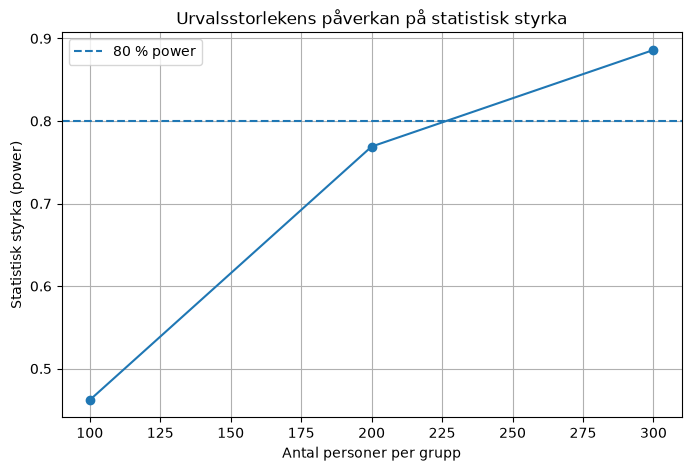

In [29]:
power_by_sample = power_results[
    power_results["mean_difference"] == 3
]

plt.figure(figsize=(8, 5))

plt.plot(
    power_by_sample["sample_size"],
    power_by_sample["power"],
    marker="o"
)

plt.axhline(
    y=0.80,
    linestyle="--",
    label="80 % power"
)

plt.xlabel("Antal personer per grupp")
plt.ylabel("Statistisk styrka (power)")
plt.title("Urvalsstorlekens påverkan på statistisk styrka")
plt.legend()
plt.grid()

plt.show()

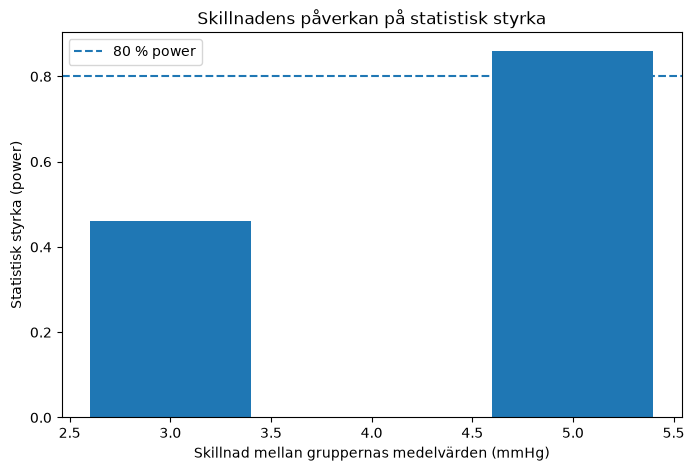

In [30]:
power_by_difference = power_results[
    power_results["sample_size"] == 100
]

plt.figure(figsize=(8, 5))

plt.bar(
    power_by_difference["mean_difference"],
    power_by_difference["power"]
)

plt.axhline(
    y=0.80,
    linestyle="--",
    label="80 % power"
)

plt.xlabel("Skillnad mellan gruppernas medelvärden (mmHg)")
plt.ylabel("Statistisk styrka (power)")
plt.title("Skillnadens påverkan på statistisk styrka")
plt.legend()

plt.show()

### 6.2 Tolkning av power-simuleringen

Simuleringen visar att statistisk styrka påverkas av både urvalsstorlek och skillnaden mellan gruppernas medelvärden.

När urvalsstorleken ökade från 100 till 200 och sedan 300 personer per grupp ökade power från 48,8 % till 77,2 % respektive 86,8 %, med en konstant skillnad på 3 mmHg.

När skillnaden mellan gruppernas medelvärden ökade från 3 till 5 mmHg, med 100 personer per grupp, ökade power från 48,8 % till 86,0 %.

Resultaten visar att både större urval och större skillnader mellan grupperna kan öka den statistiska styrkan.

Låg power innebär en större risk för typ II-fel, vilket betyder att testet misslyckas med att upptäcka en verklig skillnad.

## 7. Metodval

### Beskrivande statistik

Vi använder medelvärde, median, minimum och maximum för att sammanfatta datasetets numeriska variabler. Dessa mått ger en överblick över datans centrala värden och variation.

### Simulering

Vi använder NumPys binomialfördelning för att simulera personer med eller utan sjukdom. Eftersom sjukdomsvariabeln innehåller värdena 0 och 1 passar en binomialmodell med n=1.

### Konfidensintervall

Vi använder både normalapproximation och bootstrap för att uppskatta osäkerheten kring medelvärdet av systoliskt blodtryck. Genom att jämföra metoderna kan vi undersöka om de ger liknande resultat.

### Hypotesprövning

Vi använder Welch's t-test eftersom vi jämför medelvärdet mellan två oberoende grupper och inte förutsätter att grupperna har samma varians. Ett ensidigt test används eftersom frågeställningen undersöker om rökare har högre blodtryck.

### Power-simulering

Vi använder simulering för att undersöka hur urvalsstorlek och skillnad mellan gruppmedelvärden påverkar sannolikheten att upptäcka en verklig skillnad.